![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 2.0. Coupler Design

## 0. Imports 

### 0.1. General libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td
import gplugins.tidy3d as gt

nm = 1e-3
wavelength = np.linspace(1500, 1600) * nm
f = td.C_0 / wavelength


### 0.2. Functions by us

In [2]:
from upvfab_design_tools import MMI_EME, DC_EME

In [3]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)

## LO.1. Directional coupler length and coupling coefficient

The total power transferred to the output is modeled using the coupling coefficient (K). This coefficient depends on the relationship between the physical length of the coupling region and the beating length:

<img src="k.png" alt="Coupling Coefficient Equation" width="400">

Simulate a directional coupler that implements two deep waveguide cores of 1.2 microns width and with a gap of 600 nm between them. 
- Plot the transfer function: K vs L/Lpi
- Comment the results: distance needed for a complete energy transfer between waveguides, distance needed for splitting power in half.. 

## LO.2. 2x2 Directional Coupler

Here, you will use some functions provided by us (check **0. Imports** for more details) to simulate the propagation in a 2x2 directional coupler. Please read all the comments in the following code carefully and **make changes only to the lines marked with the #Student tag**

In [5]:
# Simulation flow for Directional Couplers
# Define your geometrical parameters here
wg_gap = 600*nm # Student. Gap between waveguides
wg_width = 1.2 # Student. Core waveguides width

d = wg_width + wg_gap
wg_N = 2

m = DC_EME() # Here you instantiate a Directional Coupler to be simulated with the Eigen-mode expansion (EME) algorithm.
m.MMI_num_modes = 12 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                    # the propagation based on the mode decomposition. 
m.DC_wg_gap = wg_gap # Gap between waveguides
m.DC_wg_width = wg_width # Width of the waveguides core
m.DC_N_waveguides = wg_N

# 1) Compute de DC modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
m.find_all_modes()

# 2) Get the L_pi 
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  94.02742605179662  µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


DC length = 9.403 um


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/188 [00:00<?, ?it/s]

------- Pameters -------
MMI length 9.4027
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9688
Total OUT power: 0.9583
Excess loss [dB] =  0.1851
------------------------
Power over OUTs:  ['0.9336', '0.0246']
Ratio over OUTs ['0.9743', '0.0257']
DC length = 29.253 um


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/585 [00:00<?, ?it/s]

... (21 outputs left out)

------- Pameters -------
MMI length 168.2046
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9688
Total OUT power: 0.9583
Excess loss [dB] =  0.1851
------------------------
Power over OUTs:  ['0.8557', '0.1025']
Ratio over OUTs ['0.8930', '0.1070']
DC length = 188.055 um


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/3761 [00:00<?, ?it/s]

------- Pameters -------
MMI length 188.0549
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9688
Total OUT power: 0.9583
Excess loss [dB] =  0.1851
------------------------
Power over OUTs:  ['0.9570', '0.0012']
Ratio over OUTs ['0.9987', '0.0013']


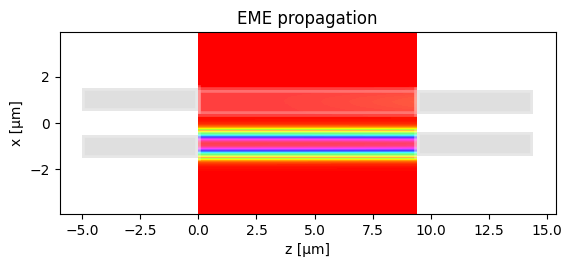

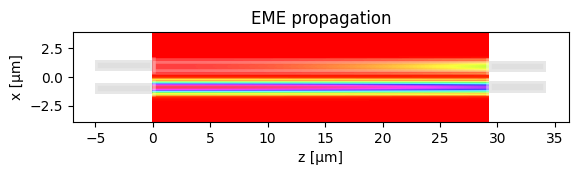

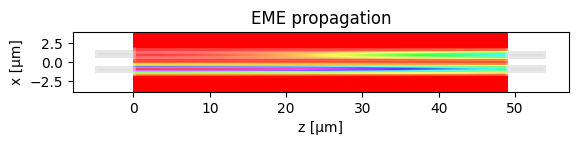

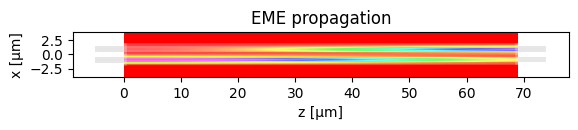

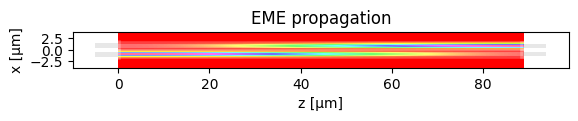

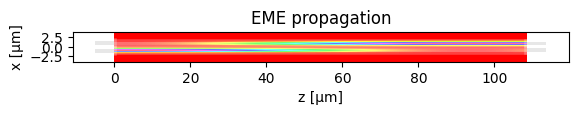

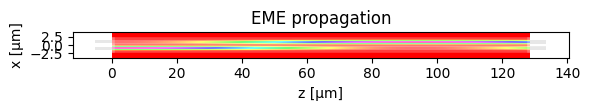

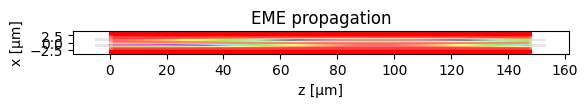

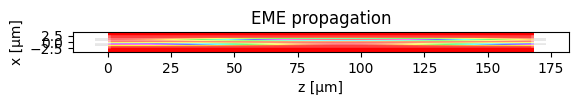

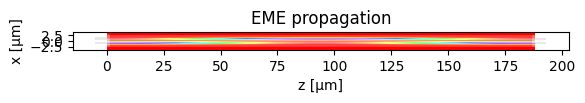

In [6]:
# IMPORTANT!!! 
# # If you DON'T change any geometrical parameter
# (waveguide widths or gap) you can skip last cell. 
# YOU CAN RUN the lines below as many times as you wish
# (SAVES TIME)

# 3) Configure DC
# DC I/O number
m.n_IN = 2
m.n_OUT = 2

L_values=np. linspace(0.1, 2, 10) * L_pi # Since we use the same library for propagation simulations of MMI and DC 
                    # some variables might be identified as "MMI". Sorry about that (: 
                    # Might change in the future 
k=np.sin(np.pi/2 * L_values/L_pi)**2 # Power transfer function for a directional coupler
# 4) Run propagation - get power transfer and plot propagation
for L in L_values:
    m.L_MMI=L
    print(f"DC length = {L:.3f} um")
    m.propagation()

c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  20.228245994634477  µm
DC length = 49.103 um


c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/982 [00:00<?, ?it/s]

------- Pameters -------
MMI length 49.1032
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.6912
Total OUT power: 0.6654
Excess loss [dB] =  1.7689
------------------------
Power over OUTs:  ['0.4071', '0.2583']
Ratio over OUTs ['0.6118', '0.3882']


... (50 outputs left out)

c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/982 [00:00<?, ?it/s]

------- Pameters -------
MMI length 49.1032
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9811
Total OUT power: 0.9161
Excess loss [dB] =  0.3804
------------------------
Power over OUTs:  ['0.7915', '0.1246']
Ratio over OUTs ['0.8640', '0.1360']


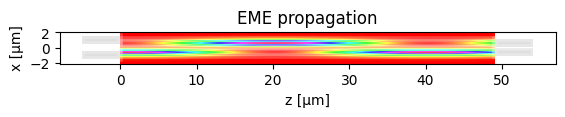

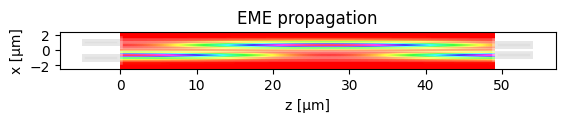

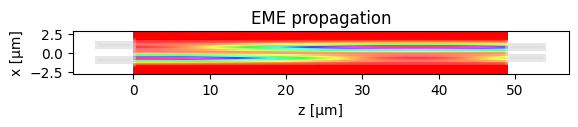

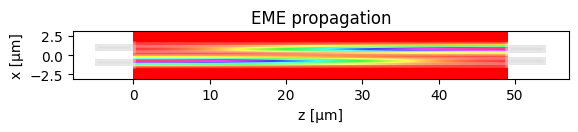

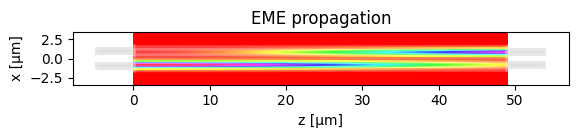

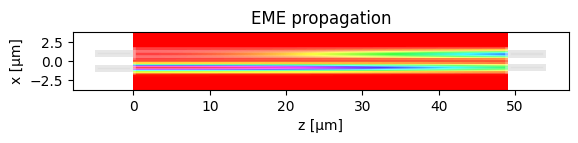

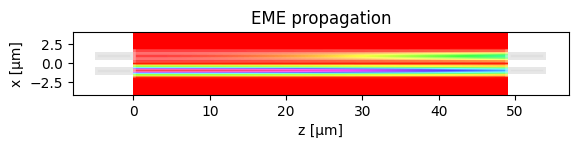

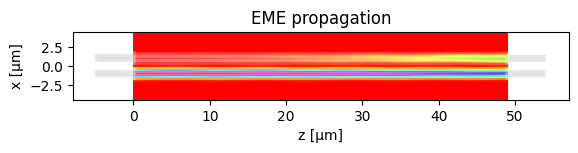

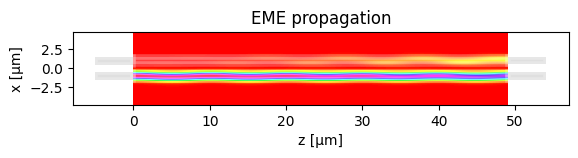

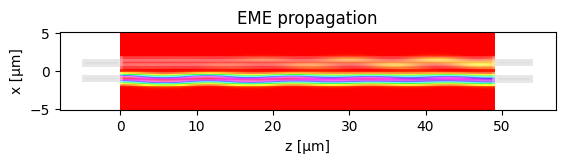

In [6]:
# Simulation flow for Directional Couplers
# Define your geometrical parameters here
wg_gap = 600*nm # Student. Gap between waveguides
wg_width = np.linspace(0.6,1.6,10) # Student. Core waveguides width

d = wg_width + wg_gap
wg_N = 2

# IMPORTANT!!! 
# # If you DON'T change any geometrical parameter
# (waveguide widths or gap) you can skip last cell. 
# YOU CAN RUN the lines below as many times as you wish
# (SAVES TIME)

# 3) Configure DC
# DC I/O number


L_values= 49.1032 # Since we use the same library for propagation simulations of MMI and DC 
                    # some variables might be identified as "MMI". Sorry about that (: 
                    # Might change in the future 

# 4) Run propagation - get power transfer and plot propagation
for wg in wg_width:

    m = DC_EME() # Here you instantiate a Directional Coupler to be simulated with the Eigen-mode expansion (EME) algorithm.
    m.MMI_num_modes = 12 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                        # the propagation based on the mode decomposition. 
    m.DC_wg_gap = wg_gap # Gap between waveguides
    m.DC_wg_width = wg # Width of the waveguides core
    m.DC_N_waveguides = wg_N
    m.n_IN = 2
    m.n_OUT = 2
    # 1) Compute de DC modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
    m.find_all_modes()

    # 2) Get the L_pi 
    L_pi = m.get_L_pi()
    k=np.sin(np.pi/2 * L_values/L_pi)**2 # Power transfer function for a directional coupler
    print("L_pi = ", L_pi, " µm")
    m.L_MMI=L_values
    print(f"DC length = {L_values:.3f} um")
    m.propagation()

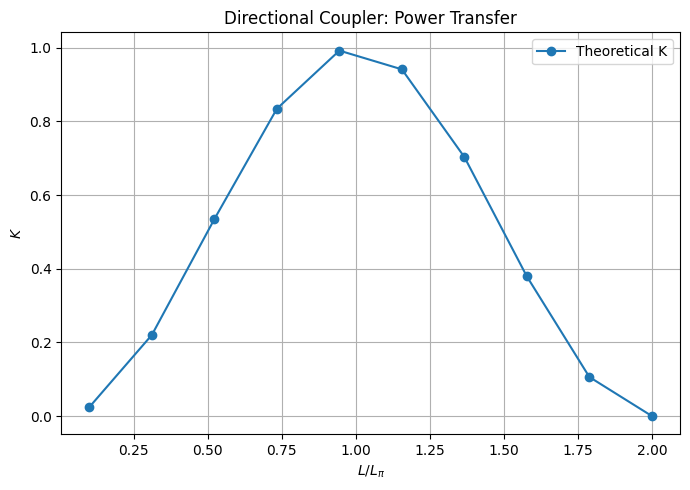

In [7]:
L_norm= L_values/L_pi
plt.figure(figsize=(7, 5))
plt.plot(L_norm, k, 'o-', label='Theoretical K')

plt.xlabel(r'$L/L_\pi$')
plt.ylabel(r'$K$')
plt.title('Directional Coupler: Power Transfer')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## LO.3. Parallel uncoupled waveguides

In [4]:
# Parameters
K_target = 0.01
L_DC = 10000  # um
wg_width = 1.0
wavelength = 1.55  # um

# Gap sweep
gap_values = np.linspace(3,5, 14)

L_pi_values = []
K_values = []

for gap in gap_values:

    m = DC_EME()

    m.wavelength = wavelength
    m.DC_wg_gap = gap
    m.DC_wg_width = wg_width
    m.DC_N_waveguides = 2

    m.MMI_num_modes = 12

    m.find_all_modes()

    L_pi = m.get_L_pi()

    K = np.sin(np.pi * L_DC / (2 * L_pi))**2

    L_pi_values.append(L_pi)
    K_values.append(K)

    print(f"Gap = {gap:.3f} um | "
          f"L_pi = {L_pi:.3f} um | K = {K:.6f}")

L_pi_values = np.array(L_pi_values)
K_values = np.array(K_values)

# Find minimum gap satisfying K < 0.01
valid_indices = np.where(K_values < K_target)[0]

if len(valid_indices) > 0:

    idx = valid_indices[0]
    best_gap = gap_values[idx]

    print("\nMinimum gap satisfying K < 0.01:")
    print(f"Gap = {best_gap:.3f} um")
    print(f"K = {K_values[idx]:.6f}")
    print(f"L_pi = {L_pi_values[idx]:.3f} um")

else:
    print("No gap in the sweep satisfies K < 0.01")
plt.figure(figsize=(8, 5))

plt.plot(gap_values, K_values, 'o-', label='Deep DC')

plt.axhline(
    y=0.01,
    color='r',
    linestyle='--',
    label='Uncoupled limit (K = 0.01)'
)

if len(valid_indices) > 0:
    plt.axvline(
        x=best_gap,
        color='g',
        linestyle='--',
        label=f'Minimum gap = {best_gap:.3f} µm'
    )

plt.xlabel('Gap (µm)')
plt.ylabel('Coupling coefficient K')
plt.title('Deep Directional Coupler: K vs Gap')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 3.000 um | L_pi = -39758.253 um | K = 0.148139


c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 3.154 um | L_pi = 59520.885 um | K = 0.068045


c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 3.308 um | L_pi = 88958.257 um | K = 0.030857


c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 3.462 um | L_pi = 131495.358 um | K = 0.014202


c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


ValueError: Point is outside of the mesh.


========== Shallow DC ==========


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 0.200 um | L_pi = 17.662 um | K = 0.095832


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 0.300 um | L_pi = 24.160 um | K = 0.024502


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


... (19 outputs left out)

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 1.400 um | L_pi = 554.341 um | K = 0.003834


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


Gap = 1.500 um | L_pi = 728.494 um | K = 0.172959

Shallow DC:
Minimum sampled gap = 0.400 um
K = 0.004938


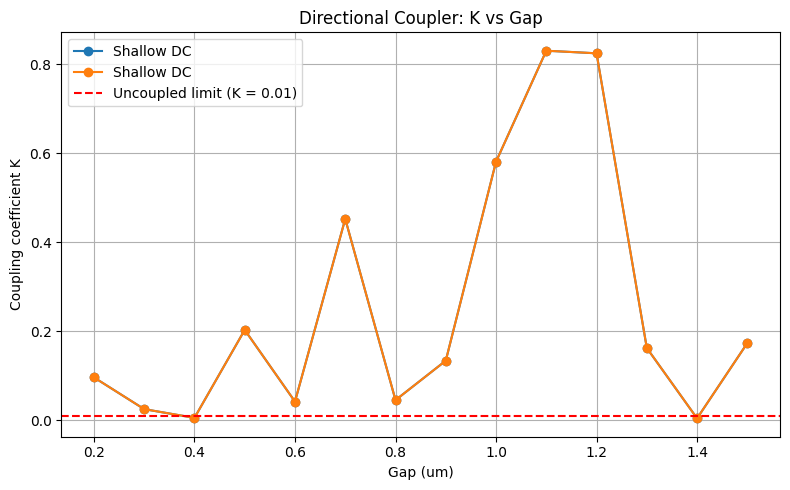

In [ ]:

# DEEP vs SHALLOW DIRECTIONAL COUPLER
# K vs GAP
# =====================================================

# Parameters
L_DC = 10000             # Parallel waveguide length (um) = 10 mm
wg_width = 1.0           # Waveguide width (um)
wavelength = 1550 * nm   # Operating wavelength

K_target = 0.01

# Gap sweep (um)
gap_values = np.linspace(0.2, 1.5, 14)

# Geometries
slab_deep = 0 * nm
slab_shallow = 100 * nm  # Replace with lab value

geometries = {
    "Deep": slab_deep,
    "Shallow": slab_shallow
}

results = {}

# Calculate L_pi and K for each geometry
# =====================================================



L_pi_values = []
K_values = []

print(f"\n========== {"Shallow"} DC ==========")

for gap in gap_values:

        m = DC_EME()

        m.wavelength = wavelength
        m.DC_wg_gap = gap
        m.DC_wg_width = wg_width
        m.DC_N_waveguides = 2

        # Set the geometry
        m.slab_thickness = slab_shallow

        m.MMI_num_modes = 12

        m.find_all_modes()

        L_pi = m.get_L_pi()

        # Coupling coefficient
        K = np.sin(np.pi * L_DC / (2 * L_pi))**2

        L_pi_values.append(L_pi)
        K_values.append(K)

        print(
            f"Gap = {gap:.3f} um | "
            f"L_pi = {L_pi:.3f} um | "
            f"K = {K:.6f}"
        )

        results = {
        "L_pi": np.array(L_pi_values),
        "K": np.array(K_values)
    }
# Find minimum gap satisfying K < 0.01
# =====================================================

K_values = np.array(K_values)

valid_indices = np.where(K_values < K_target)[0]

print(f"\n{"Shallow"} DC:")

if len(valid_indices) > 0:

    idx = valid_indices[0]

    print(f"Minimum sampled gap = {gap_values[idx]:.3f} um")
    print(f"K = {K_values[idx]:.6f}")

else:
    print("No gap in the selected range satisfies K < 0.01")


# Plot K vs GAP
# =====================================================

plt.figure(figsize=(8, 5))



plt.plot(
        gap_values,
        results['K'],
        'o-',
        label=f'Shallow DC'
    )

plt.axhline(
    y=K_target,
    color='r',
    linestyle='--',
    label='Uncoupled limit (K = 0.01)'
)

plt.xlabel('Gap (um)')
plt.ylabel('Coupling coefficient K')
plt.title('Directional Coupler: K vs Gap')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


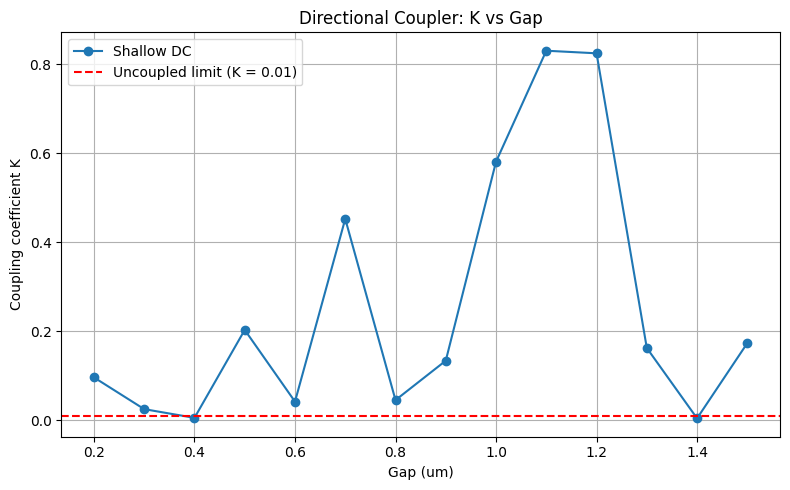

In [17]:
plt.figure(figsize=(8, 5))



plt.plot(
        gap_values,
        results['K'],
        'o-',
        label=f'Shallow DC'
    )

plt.axhline(
    y=K_target,
    color='r',
    linestyle='--',
    label='Uncoupled limit (K = 0.01)'
)

plt.xlabel('Gap (um)')
plt.ylabel('Coupling coefficient K')
plt.title('Directional Coupler: K vs Gap')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## LO.4. 2x2 Multimode Interference Coupler

### LO.4.1 Propagation Simulation

For the multimode interference (MMI) couplers we must rely on the design tables shown on the theoretical session: 

<img src="mmi.png" alt="Design tables for MMI couplers" width="600">

Here, you will use some functions provided by us (check **0. Imports** for more details) to simulate the propagation in a 2x2 directional coupler. Please read all the comments in the following code carefully and **make changes only to the lines marked with the #Student tag**

In [9]:
# Simulation flow for MMI Couplers
# Define your geometrical parameters here
mmi_Width = 10 # Student. Body width

m = MMI_EME() # Here you instantiate a MMI to be simulated with the Eigen-mode expansion (EME) algorithm.
m.MMI_width = mmi_Width
m.MMI_num_modes = 20 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                    # the propagation based on the mode decomposition. 

# 1) Compute de MMI body modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
m.find_all_modes()

# 2) Get the L_pi 
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  153.70714915414115  µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/4611 [00:00<?, ?it/s]

------- Pameters -------
MMI length 230.5607
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9665
Total OUT power: 0.5898
Excess loss [dB] =  2.2933
------------------------
Power over OUTs:  ['0.4208', '0.1689']
Ratio over OUTs ['0.7136', '0.2864']


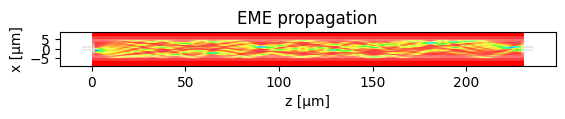

In [10]:
# IMPORTANT!!! 
# # If you DON'T change neither the MMI width 
# nor input/output waveguide widths
# YOU CAN RUN the lines below as many times as you wish
# (SAVES TIME)
mmi_Width1 = 5
# 3) Configure MMI
# # MMI I/O number (check class slides for type of MMI)
m.n_IN = 2 # STUDENT
m.n_OUT = 2 # STUDENT

# MMI I/O waveguide positions (check class slides for type of MMI)
m.IN_WVG_positions = [-mmi_Width1/6, mmi_Width1/6] # STUDENT
m.OUT_WVG_positions = [-mmi_Width1/6, mmi_Width1/6] # STUDENT

# MMI length (check class slides for type of MMI)
m.L_MMI =3*L_pi/2 # STUDENT

# Run propagation
m.propagation()

### LO.4.2. 2x2 Multimode Interference Coupler - Optimization

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


I/O width = 1.00 µm
L_pi = 40.784070916512604 µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/1224 [00:00<?, ?it/s]

------- Pameters -------
MMI length 61.1761
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9355
Total OUT power: 0.4963
Excess loss [dB] =  3.0422
------------------------
Power over OUTs:  ['0.4323', '0.0641']
Ratio over OUTs ['0.8709', '0.1291']


... (56 outputs left out)

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/1224 [00:00<?, ?it/s]

------- Pameters -------
MMI length 61.1761
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9388
Total OUT power: 0.7236
Excess loss [dB] =  1.4051
------------------------
Power over OUTs:  ['0.6595', '0.0641']
Ratio over OUTs ['0.9114', '0.0886']


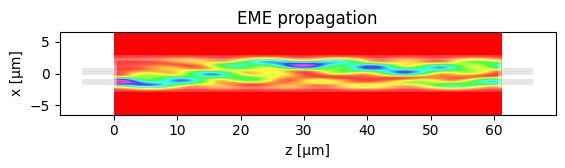

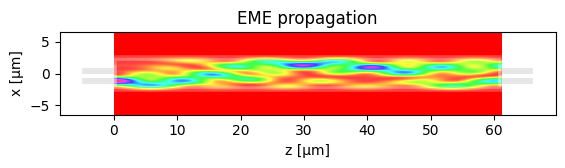

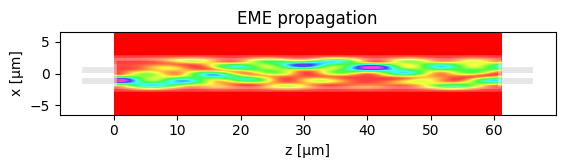

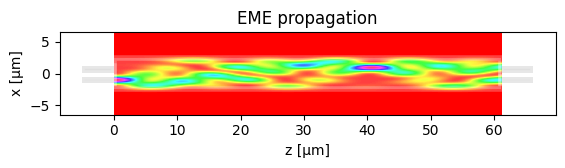

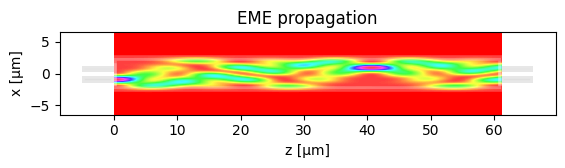

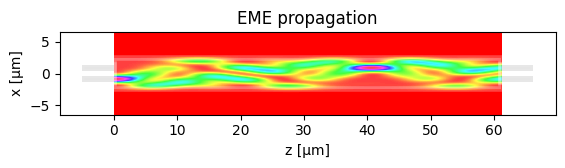

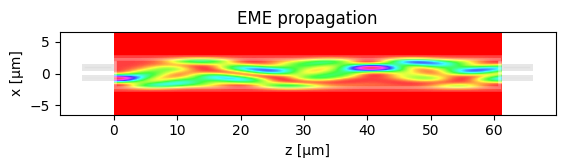

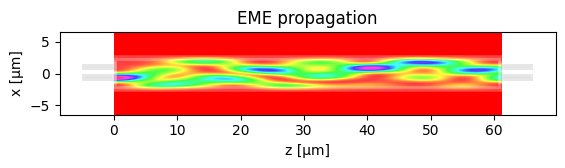

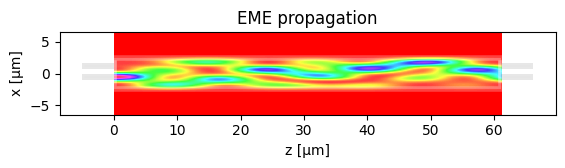

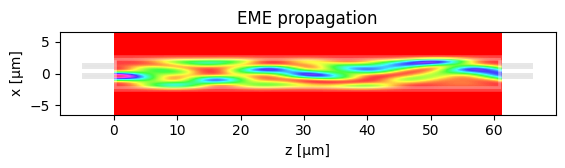

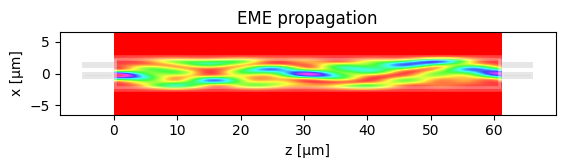

In [35]:
dy_dw = np.arange(-0.5, 0.6, 0.1)
# # MMI I/O number (check class slides for type of MMI)
m.n_IN = 2 
m.n_OUT = 2 

for dy in dy_dw:

    m = MMI_EME()
    m.MMI_width = 5   # MMI width
    # MMI I/O waveguide positions (check class slides for type of MMI)
    m.IN_WVG_positions = [-m.MMI_width/6+dy, m.MMI_width/6+dy] 
    m.OUT_WVG_positions = [-m.MMI_width/6+dy, m.MMI_width/6+dy] 

    m.find_all_modes()

    L_pi = m.get_L_pi()
    

    print(f"I/O width = {wg_width:.2f} µm")
    print(f"L_pi = {L_pi} µm")

    # MMI length (check class slides for type of MMI)
    m.L_MMI = 3*L_pi/2  
    m.dL_MMI = 0

    # Run propagation
    m.propagation()

### LO.4.3 2x2 Multimode Interference Coupler – Optimization (II)

In [30]:
# Design flow for MMI

m = MMI_EME()
m.MMI_width = 6.6   # MMI width
m.wg_width_dw = 0.1 # STUDENT

# 1) Compute de MMI modes
m.find_all_modes()

# 2) Get the L_pi
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  69.03598607256141  µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/2271 [00:00<?, ?it/s]

------- Pameters -------
MMI length 103.5540
MMI length increment 10.0000
IO wg width 1.0000
IO wg width increment 0.1000
------------------------
Total power IN coupled 0.9647
Total OUT power: 0.3157
Excess loss [dB] =  5.0072
------------------------
Power over OUTs:  ['0.3031', '0.0126']
Ratio over OUTs ['0.9600', '0.0400']


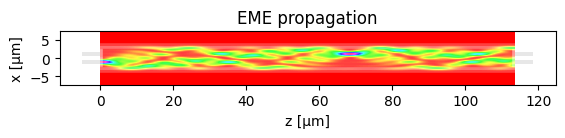

In [31]:
# 3) Configure MMI
# # MMI I/O number (check class slides for type of MMI)
m.n_IN = 2 # STUDENT
m.n_OUT = 2 # STUDENT

dy = 0.0
# MMI I/O waveguide positions (check class slides for type of MMI)
m.IN_WVG_positions = [-m.MMI_width/6, m.MMI_width/6] # STUDENT
m.OUT_WVG_positions = [-m.MMI_width/6, m.MMI_width/6] # STUDENT

# MMI length (check class slides for type of MMI)
m.L_MMI = 3*L_pi/2  # STUDENT
m.dL_MMI = 10 # STUDENT

# Run propagation
m.propagation()

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


I/O width = 0.10 µm
L_pi = 69.0359860725696 µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/2071 [00:00<?, ?it/s]

------- Pameters -------
MMI length 103.5540
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.1000
------------------------
Total power IN coupled 0.9647
Total OUT power: 0.9032
Excess loss [dB] =  0.4424
------------------------
Power over OUTs:  ['0.4197', '0.4834']
Ratio over OUTs ['0.4647', '0.5353']


... (50 outputs left out)

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/2071 [00:00<?, ?it/s]

------- Pameters -------
MMI length 103.5540
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 1.0000
------------------------
Total power IN coupled 0.9989
Total OUT power: 0.9843
Excess loss [dB] =  0.0688
------------------------
Power over OUTs:  ['0.4886', '0.4957']
Ratio over OUTs ['0.4964', '0.5036']


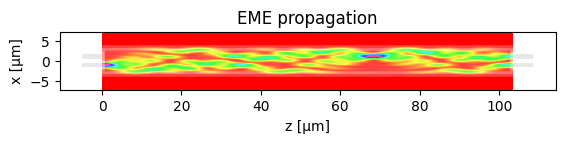

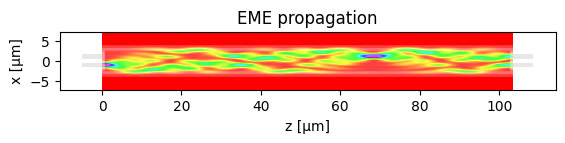

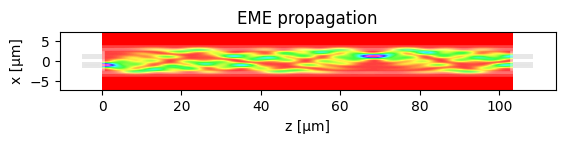

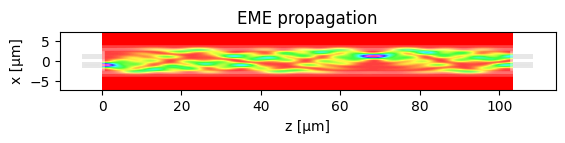

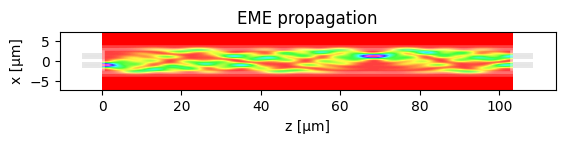

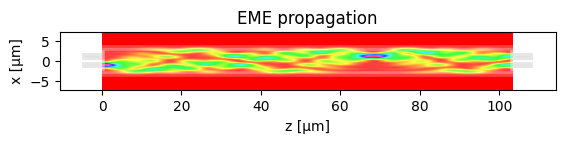

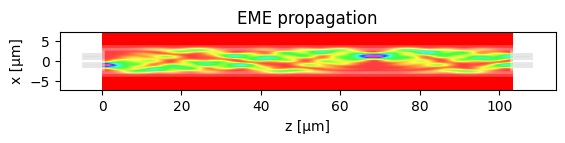

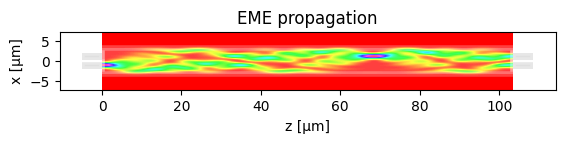

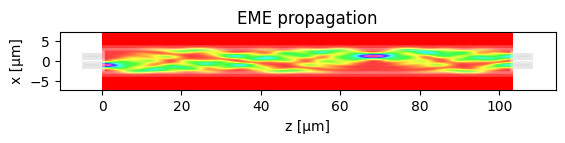

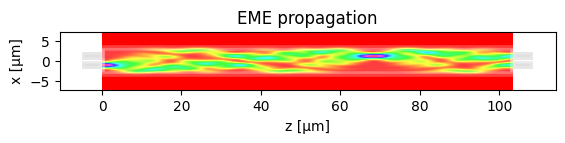

In [32]:
wg_width_dw = np.arange(0.1, 1.1, 0.1)
# # MMI I/O number (check class slides for type of MMI)
m.n_IN = 2 # STUDENT
m.n_OUT = 2 # STUDENT

dy = 0.0
for wg_width in wg_width_dw:

    m = MMI_EME()
    m.MMI_width = 6.6   # MMI width
    m.wg_width_dw = wg_width # STUDENT
    # MMI I/O waveguide positions (check class slides for type of MMI)
    m.IN_WVG_positions = [-m.MMI_width/6, m.MMI_width/6] # STUDENT
    m.OUT_WVG_positions = [-m.MMI_width/6, m.MMI_width/6] # STUDENT

    m.find_all_modes()

    L_pi = m.get_L_pi()
    

    print(f"I/O width = {wg_width:.2f} µm")
    print(f"L_pi = {L_pi} µm")

    # MMI length (check class slides for type of MMI)
    m.L_MMI = 3*L_pi/2  # STUDENT
    m.dL_MMI = 0 # STUDENT

    # Run propagation
    m.propagation()
    # Replace with the actual I/O width attribute
    m.IO_width = wg_width



## LO.5. 1x4 1x4 Multimode Interference Coupler 

Repeat the design procedure explained for the 2x2 Coupler to design a 1x4 MMI Coupler. Consider: 
- Select a suitable MMI body width, taking into account that you now must allocate 4 waveguides at the output. 
- Minimize the losses and output imbalance for the MMI coupler. 

In [33]:
# Simulation flow for MMI Couplers
# Define your geometrical parameters here
mmi_Width = 12 # Student. Body width

m = MMI_EME() # Here you instantiate a MMI to be simulated with the Eigen-mode expansion (EME) algorithm.
m.MMI_width = mmi_Width
m.MMI_num_modes = 20 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                    # the propagation based on the mode decomposition. 

# 1) Compute de MMI body modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
m.find_all_modes()

# 2) Get the L_pi 
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  219.13931544088956  µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/3287 [00:00<?, ?it/s]

------- Pameters -------
MMI length 164.3545
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9329
Total OUT power: 0.1110
Excess loss [dB] =  9.5457
------------------------
Power over OUTs:  ['0.0017', '0.0538', '0.0538', '0.0017']
Ratio over OUTs ['0.0157', '0.4842', '0.4845', '0.0156']


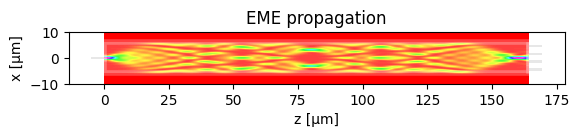

In [34]:
# IMPORTANT!!! 
# # If you DON'T change neither the MMI width 
# nor input/output waveguide widths
# YOU CAN RUN the lines below as many times as you wish
# (SAVES TIME)

# 3) Configure MMI
# # MMI I/O number (check class slides for type of MMI)
m.n_IN =  1# STUDENT
m.n_OUT = 4# STUDENT

# MMI I/O waveguide positions (check class slides for type of MMI)
m.IN_WVG_positions = [0.0] # STUDENT
m.OUT_WVG_positions = [-3*mmi_Width/8,
    -mmi_Width/8,
     mmi_Width/8,
     3*mmi_Width/8] # STUDENT

# MMI length (check class slides for type of MMI)
m.L_MMI = 3 * L_pi / 4 # STUDENT

# Run propagation
m.propagation()

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


dy = -0.20 µm
L_pi = 219.1393 µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/3287 [00:00<?, ?it/s]

------- Pameters -------
MMI length 164.3545
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9329
Total OUT power: 0.1330
Excess loss [dB] =  8.7615
------------------------
Power over OUTs:  ['0.0017', '0.0208', '0.1094', '0.0011']
Ratio over OUTs ['0.0125', '0.1563', '0.8227', '0.0085']


... (38 outputs left out)

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/3287 [00:00<?, ?it/s]

------- Pameters -------
MMI length 164.3545
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9329
Total OUT power: 0.1190
Excess loss [dB] =  9.2428
------------------------
Power over OUTs:  ['0.0013', '0.0902', '0.0257', '0.0018']
Ratio over OUTs ['0.0110', '0.7581', '0.2160', '0.0149']


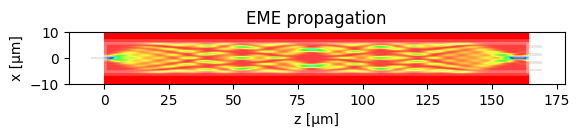

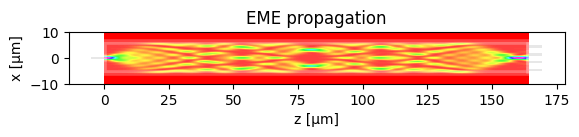

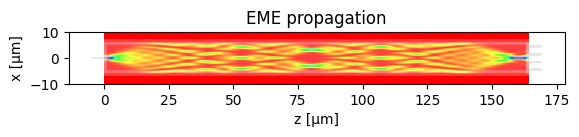

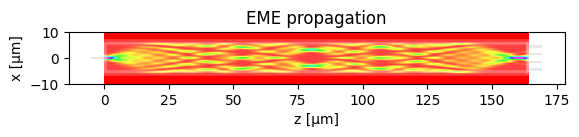

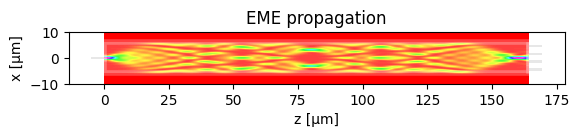

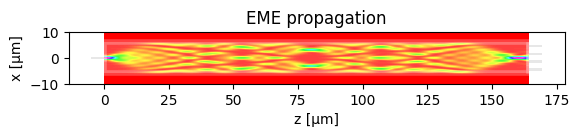

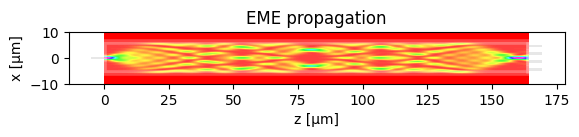

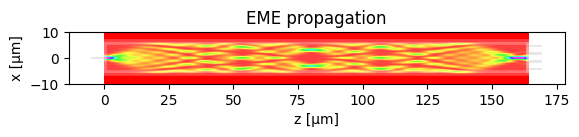

In [38]:
dy_dw = np.arange(-0.2, 0.2, 0.05)

mmi_Width = 12

for dy in dy_dw:

    m = MMI_EME()

    # MMI geometry
    m.MMI_width = mmi_Width

    # Number of input/output waveguides
    m.n_IN = 1
    m.n_OUT = 4

    # Input/output waveguide positions
    m.IN_WVG_positions = [0.0]

    m.OUT_WVG_positions = [
        -3*mmi_Width/8 + dy,
        -mmi_Width/8 + dy,
         mmi_Width/8 + dy,
         3*mmi_Width/8 + dy
    ]

    # Calculate modes
    m.find_all_modes()

    L_pi = m.get_L_pi()

    print(f"dy = {dy:.2f} µm")
    print(f"L_pi = {L_pi:.4f} µm")

    # MMI length
    m.L_MMI = 3 * L_pi / 4
    m.dL_MMI = 0

    # Run propagation
    m.propagation()

### LO.5.2. 1x4 Multimode Interference Coupler - Optimization

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


dy = 0.00 µm
L_pi = 219.1393 µm


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/1687 [00:00<?, ?it/s]

------- Pameters -------
MMI length 124.3545
MMI length increment -40.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9329
Total OUT power: 0.1624
Excess loss [dB] =  7.8937
------------------------
Power over OUTs:  ['0.0569', '0.0244', '0.0243', '0.0569']
Ratio over OUTs ['0.3501', '0.1499', '0.1499', '0.3501']


... (38 outputs left out)

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/4487 [00:00<?, ?it/s]

------- Pameters -------
MMI length 194.3545
MMI length increment 30.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9329
Total OUT power: 0.3053
Excess loss [dB] =  5.1521
------------------------
Power over OUTs:  ['0.1461', '0.0067', '0.0067', '0.1460']
Ratio over OUTs ['0.4783', '0.0218', '0.0218', '0.4780']


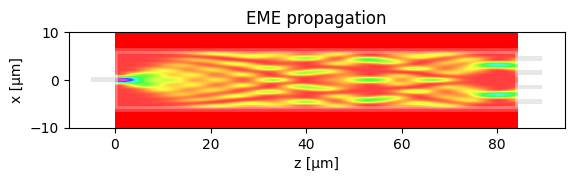

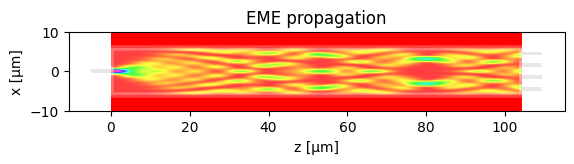

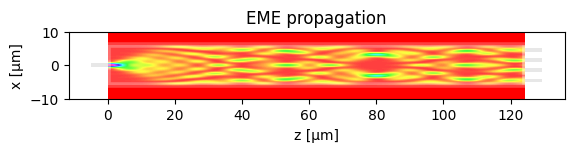

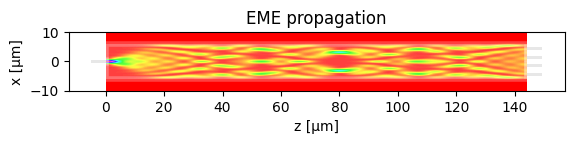

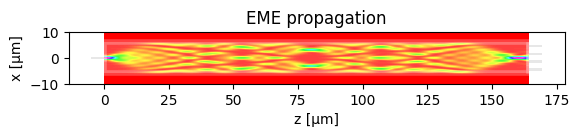

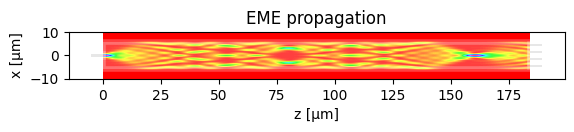

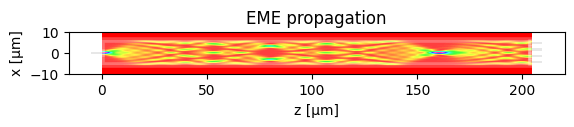

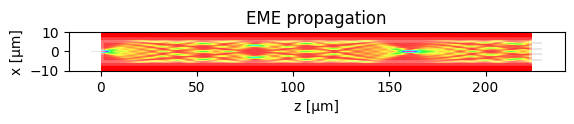

In [39]:
dL_MMI = np.arange(-40, 40, 10)
dy=0
mmi_Width = 12

for  dL in dL_MMI:

    m = MMI_EME()

    # MMI geometry
    m.MMI_width = mmi_Width

    # Number of input/output waveguides
    m.n_IN = 1
    m.n_OUT = 4

    # Input/output waveguide positions
    m.IN_WVG_positions = [0.0]

    m.OUT_WVG_positions = [
        -3*mmi_Width/8 + dy,
        -mmi_Width/8 + dy,
         mmi_Width/8 + dy,
         3*mmi_Width/8 + dy
    ]

    # Calculate modes
    m.find_all_modes()

    L_pi = m.get_L_pi()

    print(f"dy = {dy:.2f} µm")
    print(f"L_pi = {L_pi:.4f} µm")

    # MMI length
    m.L_MMI = 3 * L_pi / 4 +dL
    m.dL_MMI = dL
    # Run propagation
    m.propagation()

### LO.5.3. 1x4 Multimode Interference Coupler - Optimization (II)

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/2487 [00:00<?, ?it/s]

------- Pameters -------
MMI length 144.3545
MMI length increment -20.0000
IO wg width 1.0000
IO wg width increment 0.2500
------------------------
Total power IN coupled 0.9527
Total OUT power: 0.6645
Excess loss [dB] =  1.7749
------------------------
Power over OUTs:  ['0.1724', '0.1599', '0.1599', '0.1723']
Ratio over OUTs ['0.2594', '0.2407', '0.2407', '0.2593']


c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

... (10 outputs left out)

c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\TecnoWPc\Desktop\Master PIC\Diseño\Labs Design\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/2487 [00:00<?, ?it/s]

------- Pameters -------
MMI length 144.3545
MMI length increment -20.0000
IO wg width 1.0000
IO wg width increment 0.4500
------------------------
Total power IN coupled 0.9680
Total OUT power: 0.7062
Excess loss [dB] =  1.5104
------------------------
Power over OUTs:  ['0.1854', '0.1677', '0.1677', '0.1854']
Ratio over OUTs ['0.2625', '0.2375', '0.2375', '0.2625']


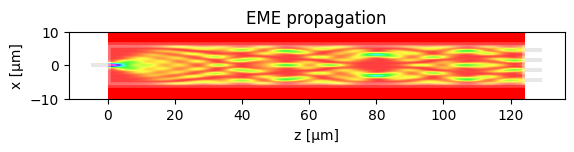

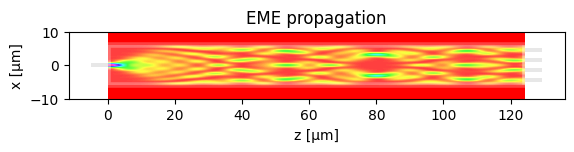

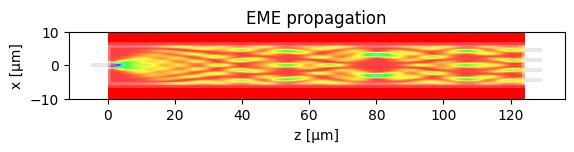

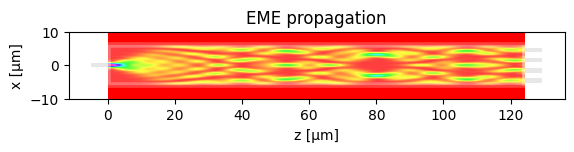

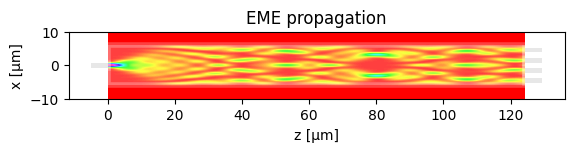

In [6]:
width_increments = np.arange(0.25, 0.50, 0.05)
mmi_Width = 12
for dw in width_increments:

    m = MMI_EME()

    m.MMI_width =mmi_Width 
    m.wg_width_dw = dw

    m.n_IN = 1
    m.n_OUT = 4

    m.IN_WVG_positions = [0.0]

    m.OUT_WVG_positions = [
        -3*mmi_Width/8,
        -mmi_Width/8,
         mmi_Width/8,
         3*mmi_Width/8
    ]

    # Recalculate modes for every width
    m.find_all_modes()

    L_pi = m.get_L_pi()

    m.L_MMI = 144.3545
    m.dL_MMI = -20

    m.propagation()

## Extra - Exercises

### E1. Directional coupler gap dependence

2026-11-16 15:08:58.532 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_b098ed94e7f5f273.npz.


c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, 

15:10:42 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

15:10:43 Hora estándar romance WARNING: Mode field at frequency index 1, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 2, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 3, mode   
                               index 3 does not decay at the plane boundaries.  

... (199 outputs left out)

                               WARNING: Mode field at frequency index 47, mode  
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 48, mode  
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 49, mode  
                               index 3 does not decay at the plane boundaries.  

2026-11-16 15:15:47.257 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_7e88b83d59cafb9d.npz.


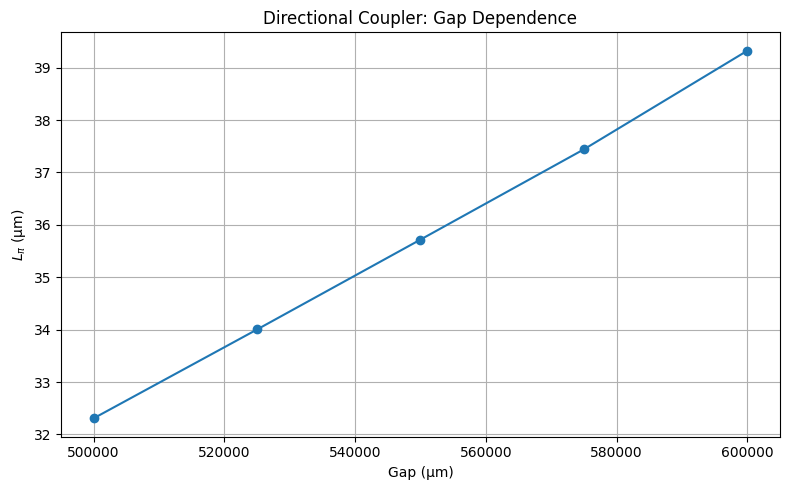

In [ ]:
# Sweep the gap between the two waveguides
gap_values = np.linspace(500,600, 5) * nm

L_pi_values = []
wavelength = np.linspace(1500, 1600) * nm
for gap in gap_values:

    dc = gt.modes.WaveguideCoupler(
        wavelength=wavelength,
        core_width=(1.0, 1.0),
        gap=gap,
        slab_thickness=150 * nm,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        num_modes=4,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20
    )

    neff = dc.n_eff

    # Beat length from the two fundamental supermodes
    L_pi = wavelength / (2 * np.abs(neff[:, 0] - neff[:, 1]))

    L_pi_values.append(np.mean(L_pi))

# Convert gap to microns

# Plot
plt.figure(figsize=(8, 5))
plt.plot(gap_values, L_pi_values, 'o-')
plt.xlabel('Gap (µm)')
plt.ylabel(r'$L_\pi$ (µm)')
plt.title('Directional Coupler: Gap Dependence')
plt.grid(True)
plt.tight_layout()
plt.show()

### E2. Directional coupler wavelength dependence

c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, 

15:17:04 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 1, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 2, mode   
                               index 3 does not decay at the plane boundaries.  

15:17:05 Hora estándar romance WARNING: Mode field at frequency index 3, mode   
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 4, mode   
                               index 3 does not decay at the plane boundaries.  

... (42 outputs left out)

                               WARNING: Mode field at frequency index 47, mode  
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 48, mode  
                               index 3 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 49, mode  
                               index 3 does not decay at the plane boundaries.  

2026-11-16 15:17:07.903 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_390f80b862084e39.npz.


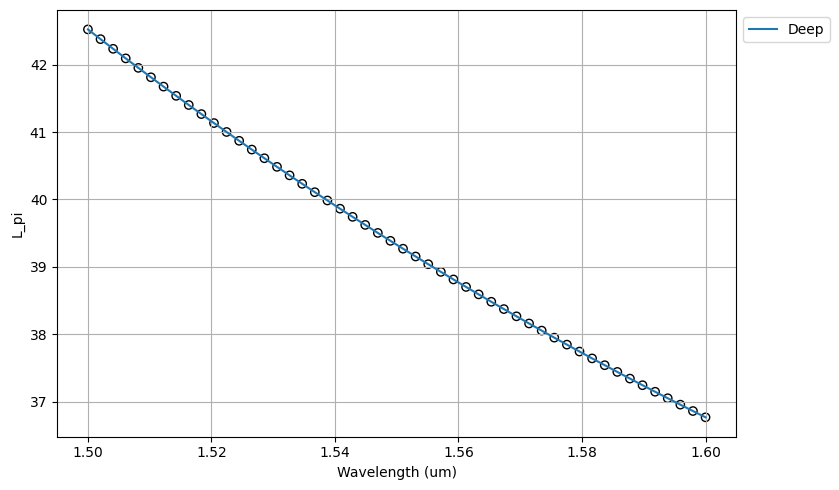

In [ ]:
wavelength = np.linspace(1.5, 1.6, 50)   # STUDENT code goes here

deep_dcoupler_cs = gt.modes.WaveguideCoupler(
    wavelength=wavelength, # Wavelength to simulate - Must be a vector
    core_width=(1.0, 1.0), # Waveguide width
    gap=600 * nm,
    slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    core_thickness=300 * nm, # Waveguide height 
    num_modes=4, # Number of modes to find
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    max_grid_scaling=1.5, # Parameters of the grid
    grid_resolution=20 # Parameters of the grid
)

deep_neff = deep_dcoupler_cs.n_eff
L_pi_TE = wavelength / (2 * np.abs(deep_neff[:, 0] - deep_neff[:, 1]))  # STUDENT code here

plt.figure(figsize=(10, 5))
plt.scatter(wavelength, L_pi_TE,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(wavelength, L_pi_TE,label='Deep')
plt.xlabel("Wavelength (um)")
plt.ylabel("L_pi")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

### E3. MMI coupler wavelength dependence

c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, 

15:51:50 Hora estándar romance WARNING: Mode '14' appears to undergo a          
                               discontinuous change between frequencies         
                               '189058306846846.84' and '187370286250000.0'     
                               (overlap: '0.00').                               

15:51:57 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 9 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 10 does not decay at the plane boundaries. 

                               WARNING: Mode field at frequency index 0, mode   
                               index 12 does not decay at the plane boundaries. 

                               WARNING: Mode field at frequency index 0, mode   
                               index 14 does not decay at the plane boundaries. 

... (44 outputs left out)

                               WARNING: Mode field at frequency index 14, mode  
                               index 7 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 14, mode  
                               index 9 does not decay at the plane boundaries.  

15:52:01 Hora estándar romance WARNING: Mode field at frequency index 14, mode  
                               index 10 does not decay at the plane boundaries. 

2026-11-16 15:52:04.750 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_0ddc5c05bf18f9df.npz.


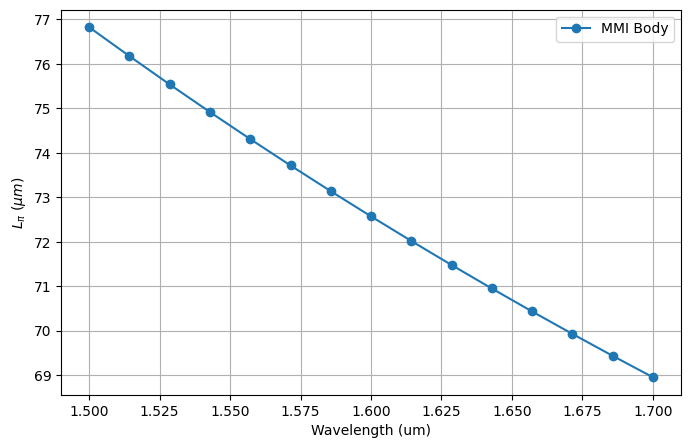

In [22]:
mmi_body_w = 6.6 
lambda_c = np.linspace(1.5, 1.7, 15)   # STUDENT code goes here.
mmi_body_waveguide = gt.modes.Waveguide(
    core_width=6.6,
    core_thickness=300 * nm,
    slab_thickness=150 * nm,
    core_material='sin',
    clad_material='sio2',
    wavelength=lambda_c,
    num_modes=15,
    max_grid_scaling=1.5,
    grid_resolution=30,  # Increased from 20
    cache_path='.cache/',
    precision='double',
)
neff = mmi_body_waveguide.n_eff.real

d_n_eff = np.abs(neff[:, 0] - neff[:, 1])

L_pi = lambda_c / (2 * d_n_eff)

plt.figure(figsize=(8, 5))
plt.plot(lambda_c, L_pi, 'o-', label='MMI Body')
plt.xlabel('Wavelength (um)')
plt.ylabel(r'$L_\pi$ ($\mu m$)')
plt.grid(True)
plt.legend()
plt.show()

### E4. MMI coupler body width dependence

c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Sergio\OneDrive - UPV\Escritorio\Master PIC\Diseño\Labs Design\pic-upv-lab2\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, 

15:25:55 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 8 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 9 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 11 does not decay at the plane boundaries. 

                               WARNING: Mode field at frequency index 0, mode   
                               index 13 does not decay at the plane boundaries. 

2026-11-16 15:25:55.817 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_8be1094f2e34de0e.npz.


... (46 outputs left out)

15:26:28 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 9 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 11 does not decay at the plane boundaries. 

                               WARNING: Mode field at frequency index 0, mode   
                               index 12 does not decay at the plane boundaries. 

2026-11-16 15:26:28.395 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\Waveguide_38632d1eb53ddcb7.npz.


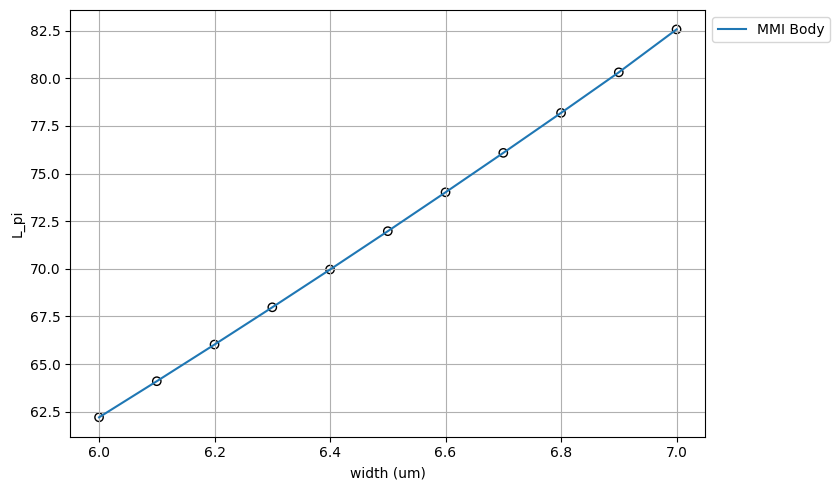

In [13]:
lambda_c = 1.55
mmi_body = np.linspace(6.0, 7.0, 11)  # STUDENT. You can manually change the body width
                 # or you can sweep the parameter using a Python for loop. 
L_pi_values = []
for mmi_body_w in mmi_body:
    mmi_body_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=mmi_body_w, # MMI Body width
    core_thickness=300 * nm, # MMI Body height 
    slab_thickness=150* nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguides.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=lambda_c, # Wavelength to simulate
    num_modes=15, # Targeted number of modes to find - Higher than before! It's a multimode section
    max_grid_scaling=1.5, # Parameters of the grid
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

    d_n_eff = mmi_body_waveguide.n_eff[0].real -  mmi_body_waveguide.n_eff[1].real

    L_pi = wavelength / (2 * np.abs(d_n_eff))  # STUDENT code goes here
    L_pi_values.append(np.mean(L_pi))
# STUDENT plot here. 
plt.figure(figsize=(10, 5))
plt.scatter(mmi_body, L_pi_values,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(mmi_body, L_pi_values,label='MMI Body')
plt.xlabel("width (um)")
plt.ylabel("L_pi")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

